## Validation strategy

All data comes from `sales_train_evaluation.csv`, split by day.
Splits are always chronological: the model never sees days after the period
it is forecasting, which prevents data leakage. Days are never split at random.

| Period | Days | Role |
|---|---|---|
| Training | `d_1` – `d_1913` | Fit the model during development |
| Validation | `d_1914` – `d_1941` | Measure WRMSSE on known sales |
| Evaluation | `d_1942` – `d_1969` | Final forecast (sales unknown) |

The work runs in two stages:

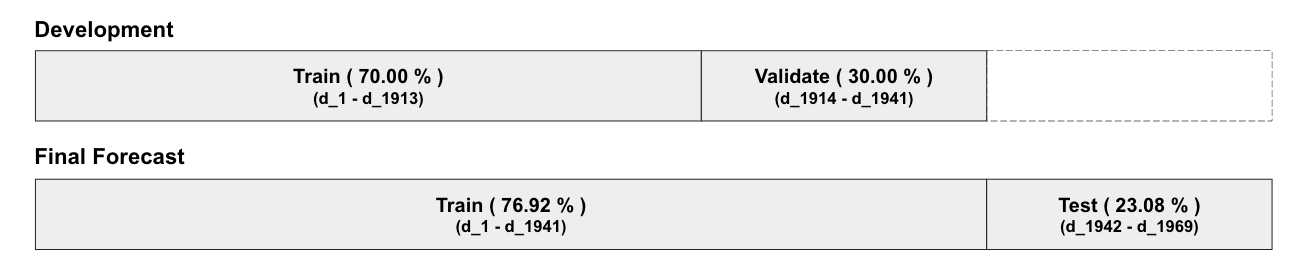

1. **Development.** Train on `d_1` – `d_1913` and forecast `d_1914` – `d_1941`.
   Compare the forecast with actual sales to compute WRMSSE.
   Feature and parameter changes are judged on this score.
2. **Final forecast.** Retrain on all data up to `d_1941` with the chosen setup,
   then forecast `d_1942` – `d_1969`. The most recent 28 days are the closest
   to the forecast period, so they are included in the final training.

Before training, each table is joined into one row per product, store and day:

- `sales_train_evaluation.csv` is reshaped from wide to long format
  (one column per day becomes one row per day).
- `calendar.csv` is joined on `d`.
- `sell_prices.csv` is joined on `store_id`, `item_id` and `wm_yr_wk`.
  Rows with no price are dropped, since the product was not yet on sale.

**Possible improvement:** A single 28-day window may fall on an unusual period.
Walk-forward validation over several windows (for example, ending at `d_1885`,
`d_1913` and `d_1941`) would give a more reliable estimate.